# Ashaar: exploration of the raw files

Ashaar is a dataset of Arabic poems published on Hugging Face by ARBML
(`arbml/ashaar`): one row per poem, with its verses, meter, poet and era.

The two Parquet files are downloaded as published, at a pinned revision
(`9b5e723df1c5b13b9e4428caff758fe2f3c737f6`), with `download_ashaar.py`, in this folder.
This notebook explores them without modifying or filtering anything; the two
files are only put end to end in memory.

**Observed** marks what the data show, **Interpretation** our own reading.

In [1]:
import pathlib

# The notebook sits in the same folder as the data files.
DATA = pathlib.Path(".")
for path in sorted(DATA.glob("*.parquet")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

train-00000-of-00002.parquet: 126,379,298 bytes
train-00001-of-00002.parquet: 150,989,177 bytes


In [2]:
import pandas as pd

# The two files are read as published and put end to end in memory;
# no file is rewritten.
parts = [pd.read_parquet(path) for path in sorted(DATA.glob("*.parquet"))]
for path, part in zip(sorted(DATA.glob("*.parquet")), parts):
    print(f"{path.name}: {len(part):,} poems")
df = pd.concat(parts, ignore_index=True)
print(f"Total: {len(df):,} poems, {df.shape[1]} columns")
print()
print(df.dtypes)

train-00000-of-00002.parquet: 127,315 poems
train-00001-of-00002.parquet: 127,315 poems
Total: 254,630 poems, 12 columns

poem title               str
poem meter               str
poem verses           object
poem theme               str
poem url                 str
poet name                str
poet description         str
poet url                 str
poet era                 str
poet location            str
poem description      object
poem language type       str
dtype: object


In [3]:
# Website the poem was collected from: domain of `poem url`
# (some URLs start with "//", without "https:").
df["source"] = (df["poem url"].str.extract(r"^(?:https?:)?//(?:www\.)?([^/]+)")[0]
                .fillna("(no url)"))
df["source"].value_counts()

source
poetry.dctabudhabi.ae    91716
poetsgate.com            70681
aldiwan.net              69103
adab.com                 20969
aldiwanalarabi.com        1875
diwany.org                 245
(no url)                    38
islamport.com                2
linga.org                    1
Name: count, dtype: int64

**Observed.** The poems come from several websites (domain of `poem url`),
mainly `poetry.dctabudhabi.ae`, `poetsgate.com` and `aldiwan.net`.

**Interpretation.** Ashaar aggregates several sites, each with its own
vocabulary. This explains many of the anomalies below.

## Structure

One row is one poem. The twelve columns:

| Column | Content |
|---|---|
| `poem title` | title of the poem |
| `poem meter` | meter (*baḥr*), as a label in Arabic |
| `poem verses` | list of strings: the text of the poem |
| `poem theme` | theme (e.g. قصيدة دينية) |
| `poem url` | address of the poem on its source website |
| `poet name` | name of the poet |
| `poet description` | short biography of the poet |
| `poet url` | address of the poet's page |
| `poet era` | era of the poet, as a label in Arabic |
| `poet location` | place of the poet |
| `poem description` | nested structure that looks like an HTML tree (interpretation) |
| `poem language type` | type of language |

The first poem, as stored:

In [4]:
poem = df.iloc[0]
for column in df.columns:
    print(f"--- {column}")
    if column == "poem verses":
        for element in poem[column]:
            print(element)
    else:
        print(poem[column])

--- poem title
أصبح الملك للذي فطر الخلق
--- poem meter
بحر الخفيف
--- poem verses
أَصبَحَ المُلك لِلَّذي فَطر الخَل
قَ بِتَقديرٍ للعَزيز العَليمِ
غافر الذَنب للمسيءِ بِعَفوٍ
قابل التَوب ذي العَطاء العَميمِ
مُرسل المُصطَفى البَشير إِلَينا
رَحمة مِنهُ بِالكَلام القَديمِ
رَبَنا رَبّنا إِلَيكَ أَنينا
فَأَجرنا مِن حَر نار الجَحيمِ
وَاكفِنا شَرّ ما نَخاف بِلُطفٍ
يا عَظيماً يَرجى لِكُل عَظيمِ
وَتَقبل أَعمالَنا وَاعفُ عَنا
وَأَنلنا دُخول دار النَعيمِ
بِنَبي بَعثَتهُ فَهَدانا
لِصِراط مِن الهُدى مُستَقيمِ
وَبِمَن نَحنُ في حِماهُ مَدى الدَهر
أَخيهِ يَحيى الحصور الكَريمِ
أَدرك أَدرك قَوماً أَتوا بافتقار
وَاِنكِسار وَمَدمَع مَسجومِ
شَهدت أَرواحَهُم أَنكَ اللَهُ
وَجاءوا بِكُل قَلبٍ سَليم
--- poem theme
قصيدة دينية
--- poem url
https://www.aldiwan.net/poem16182.html
--- poet name
الامير منجك باشا
--- poet description
منجك بن محمد بن منجك بن ابي بكر بن عبد القادر بن ابراهيم بن منجك اليوسفي الكبير
اكبر شعراء عصره من اهل دمشق من بيت امارة و رياسة
انفق في صباه ما ورثه عن ابوه و انزوى ثم رحل الى الديار ا

**Observed.** Each string of `poem verses` is a hemistich (20 strings for
10 verses). The first verse is *mudawwar*: الخلق is split in two (الخَل / قَ).
Vocalisation is partial.

## Empty fields

In [5]:
def is_empty_string(value):
    return isinstance(value, str) and value.strip() == ""

def is_empty_list(value):
    return not isinstance(value, str) and hasattr(value, "__len__") and len(value) == 0

empty = pd.DataFrame({
    "null": df.isna().sum(),
    "empty string": df.apply(lambda col: col.map(is_empty_string).sum()),
    "empty list": df.apply(lambda col: col.map(is_empty_list).sum()),
})
empty["% null"] = (100 * empty["null"] / len(df)).round(1)
empty

,null,empty string,empty list,% null
poem title,91765,20,0,36.0
poem meter,101277,0,0,39.8
poem verses,0,0,1,0.0
poem theme,187110,0,0,73.5
poem url,38,0,0,0.0
poet name,0,0,0,0.0
poet description,184719,0,0,72.5
poet url,91936,0,0,36.1
poet era,107209,0,0,42.1
poet location,190602,0,0,74.9


**Observed.** `poem meter` is missing for 40% of the poems and `poet era` for
42%. Missing fields are almost all true `null` values.

## `poem verses`: even or odd number of strings

If each string is a hemistich, every poem should have an even number of them.

In [6]:
# Number of elements in `poem verses`, per poem.
df["n_elements"] = df["poem verses"].map(len)

parity = pd.Series({
    "empty (0 elements)": (df["n_elements"] == 0).sum(),
    "odd number of elements": (df["n_elements"] % 2 == 1).sum(),
    "even number of elements (> 0)": ((df["n_elements"] > 0) & (df["n_elements"] % 2 == 0)).sum(),
}, name="poems")
parity.to_frame()

,poems
empty (0 elements),1
odd number of elements,24378
even number of elements (> 0),230251


**Observed.** 230,251 poems have an even number of elements, 24,378 an odd
number, and 1 poem has none.

## `poem meter`

In [7]:
meter = (df["poem meter"].value_counts(dropna=False).rename("poems").to_frame())
print(f"{len(meter)} values (including the empty value)")
pd.set_option("display.max_rows", 200)
meter

102 values (including the empty value)


,poems
poem meter,
NaN,101277
الطويل,19746
الكامل,16151
بحر الطويل,14823
البسيط,12198
بحر الكامل,8901
بحر البسيط,8337
الوافر,7720
الخفيف,7174


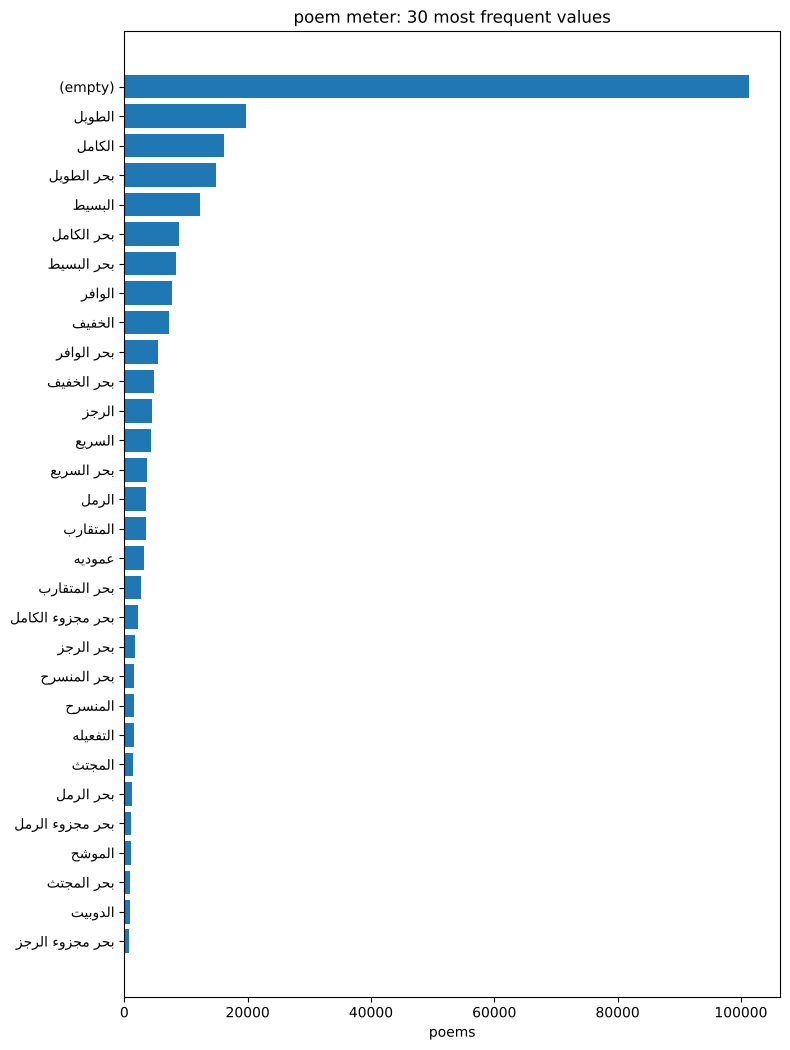

In [8]:
import matplotlib.pyplot as plt

# matplotlib 3.11+ shapes Arabic text correctly with DejaVu Sans.
plt.rcParams["font.family"] = "DejaVu Sans"

def barh(series, title, xlabel):
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(series) + 1))
    ax.barh(series.index.astype(str)[::-1], series.values[::-1])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    plt.show()

top = meter["poems"].head(30)
top.index = top.index.fillna("(empty)")
barh(top, "poem meter: 30 most frequent values", "poems")

In [9]:
# For display only: put side by side the labels that differ only by the
# prefix "بحر ". Nothing is merged in the data.
labels = meter.index.dropna()
bare = {label.removeprefix("بحر "): label for label in labels}
rows = []
for label in labels:
    if not label.startswith("بحر ") and "بحر " + label in labels:
        rows.append({
            "without بحر": label, "poems (without)": meter.loc[label, "poems"],
            "with بحر": "بحر " + label, "poems (with)": meter.loc["بحر " + label, "poems"],
        })
pd.DataFrame(rows)

,without بحر,poems (without),with بحر,poems (with)
0,الطويل,19746,بحر الطويل,14823
1,الكامل,16151,بحر الكامل,8901
2,البسيط,12198,بحر البسيط,8337
3,الوافر,7720,بحر الوافر,5508
4,الخفيف,7174,بحر الخفيف,4839
5,الرجز,4446,بحر الرجز,1682
6,السريع,4333,بحر السريع,3612
7,الرمل,3488,بحر الرمل,1297
8,المتقارب,3480,بحر المتقارب,2706
9,المنسرح,1572,بحر المنسرح,1593


poem meter,(empty),with بحر,without بحر,All
source,,,,
(no url),0,0,38,38
adab.com,20969,0,0,20969
aldiwan.net,1580,62195,5328,69103
aldiwanalarabi.com,1875,0,0,1875
diwany.org,0,245,0,245
islamport.com,0,0,2,2
linga.org,0,0,1,1
poetry.dctabudhabi.ae,6172,9,85535,91716
poetsgate.com,70681,0,0,70681


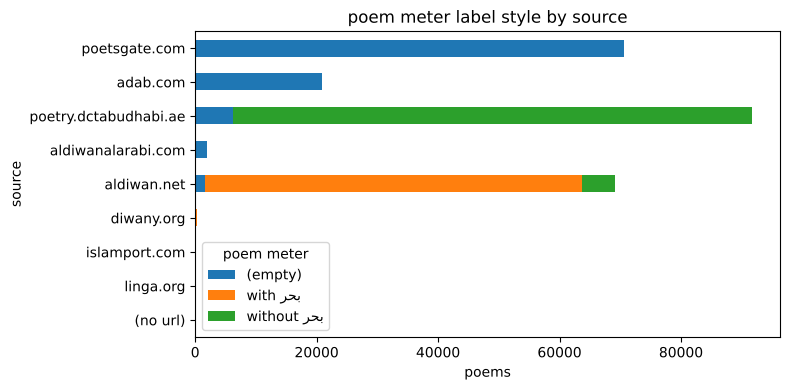

In [10]:
# Label style by source website.
def style(label):
    if pd.isna(label):
        return "(empty)"
    return "with بحر" if label.startswith("بحر ") else "without بحر"

styles = pd.crosstab(df["source"], df["poem meter"].map(style), margins=True)
display(styles)

plot = styles.drop(index="All", columns="All").sort_values("(empty)")
ax = plot.plot.barh(stacked=True, figsize=(8, 4))
ax.set_title("poem meter label style by source")
ax.set_xlabel("poems")
plt.tight_layout()
plt.show()

**Observed.** 101 distinct labels plus the empty value. The same *baḥr* is
written with or without بحر depending on the site (`aldiwan.net` with,
`poetry.dctabudhabi.ae` without). Some labels add a variant (مجزوء, مخلع, ...),
others are not *buḥūr* at all (عموديه, التفعيله, نثريه, ...). The two
بحر مجزوء الرمل differ by a trailing space.

## `poet era`

,poems,poets
poet era,,
NaN,107209,3085
العصر الحديث,55137,983
العصر العباسي,30413,644
العصر المملوكي,19059,219
العصر العثماني,11872,208
المغرب والأندلس,6614,495
العصر الفاطمي,4939,636
العصر الأندلسي,4770,15
العصر الأموي,3958,295


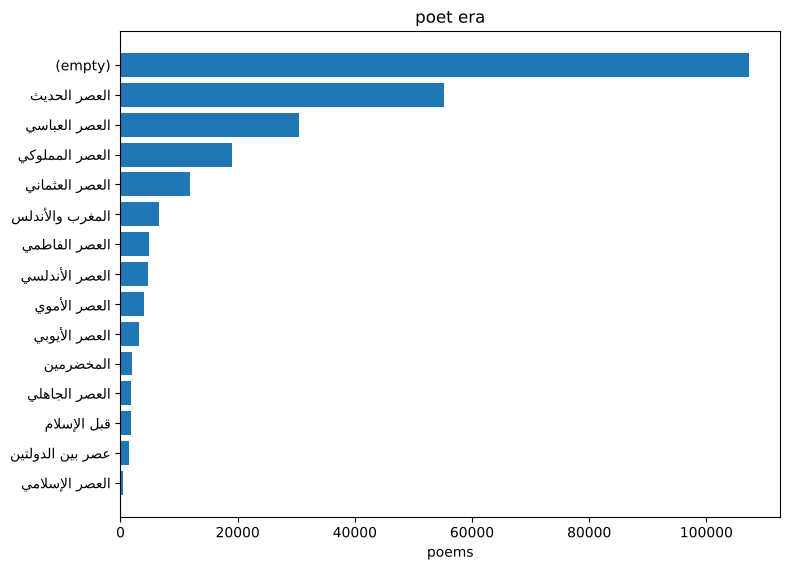

In [11]:
era = df.groupby("poet era", dropna=False).agg(
    poems=("poet name", "size"), poets=("poet name", "nunique"),
).sort_values("poems", ascending=False)
display(era)
plot = era["poems"].copy()
plot.index = plot.index.fillna("(empty)")
barh(plot, "poet era", "poems")

In [12]:
def compare_eras(first, second):
    poets = {name: set(df.loc[df["poet era"] == name, "poet name"]) for name in (first, second)}
    display(pd.DataFrame({
        "poets": [len(poets[first]), len(poets[second])],
        "poets in both": len(poets[first] & poets[second]),
    }, index=[first, second]))
    # Poets with the most poems in each category, side by side.
    tops = []
    for name in (first, second):
        top = df.loc[df["poet era"] == name, "poet name"].value_counts().head(8)
        tops.append(pd.DataFrame({f"{name}: poet": top.index, "poems": top.values}))
    display(pd.concat(tops, axis=1))

compare_eras("العصر الجاهلي", "قبل الإسلام")
compare_eras("العصر الأندلسي", "المغرب والأندلس")

,poets,poets in both
العصر الجاهلي,216,16
قبل الإسلام,507,16


,العصر الجاهلي: poet,poems,قبل الإسلام: poet,poems
0,عنترة بن شداد,141,عدي بن زيد,160
1,الخنساء,98,عَنتَرَة بن شَدّاد,123
2,النابغة الذبياني,79,أبو دؤاد الإيادي,104
3,دريد بن الصمة,75,هدبة بن الخشرم,53
4,الأسود النهشلي,74,عبد المطّلب بن هاشم,47
5,تأبط شراً,57,سَلامَة بن جَندَل,35
6,بشر بن أبي خازم,55,حاتَم الطائي,34
7,زهير بن أبي سلمى,53,عمرو بنِ قُمَيئَة,33


,poets,poets in both
العصر الأندلسي,15,4
المغرب والأندلس,495,4


,العصر الأندلسي: poet,poems,المغرب والأندلس: poet,poems
0,الشريف العقيلي,981,عبد الكريم البَسطي,323
1,ابن قلاقس,502,أبو الحسن الحصري,294
2,الأبيوردي,388,ابن سعيد المغربي,235
3,عبد الغفار الأخرس,378,ابن ليون التجيبي,204
4,ابن حمديس,365,أبو الصلت الداني,191
5,ظافر الحداد,317,ابن فُركون,190
6,الأرجاني,314,ابن حزم الأندلسي,172
7,عمارة اليمني,314,ابن رشيق القيرواني,162


In [13]:
# Where do the poems of each era category come from?
# Only the sites that give an era to at least one poem are shown.
eras_by_source = pd.crosstab(df["poet era"], df["source"])
eras_by_source.loc[:, eras_by_source.sum() > 0]

source,aldiwan.net,poetry.dctabudhabi.ae
poet era,,
العصر الأموي,0,3958
العصر الأندلسي,4770,0
العصر الأيوبي,0,3125
العصر الإسلامي,0,484
العصر الجاهلي,1873,0
العصر الحديث,15380,39757
العصر العباسي,18128,12285
العصر العثماني,5097,6775
العصر الفاطمي,0,4939


**Observed.** 42% of the poems (about 107k) have no era. The era vocabulary
depends on the site: `aldiwan.net` uses العصر الجاهلي and العصر الأندلسي,
`poetry.dctabudhabi.ae` uses قبل الإسلام and المغرب والأندلس. Only two sites give an era, and most era labels are used by only one of them.
The same poet can be written differently (عنترة بن شداد / عَنتَرَة بن شَدّاد).

**Interpretation.**
- العصر الجاهلي (`aldiwan.net`) and قبل الإسلام (`poetry.dctabudhabi.ae`) seem to
  be the same category under two names. Some categories should probably be
  merged.
- العصر الأندلسي on `aldiwan.net` does not seem to mean "Andalusian": except for
  Ibn Ḥamdīs, its main poets are known as poets of Egypt, Iraq, Persia or Yemen.
  This label is unreliable.
- The same poem may exist on several sites, so the corpus may contain
  duplicates across sources.

## The *ṭawīl*

We look at the *ṭawīl* in particular because it is the *baḥr* the thesis
starts with. Its labels are found by matching the names of the sixteen
*buḥūr*.

In [14]:
# The sixteen buḥūr of classical ʿarūḍ (al-Khalīl's fifteen and al-Akhfash's
# mutadārak). This list comes from the ʿarūḍ tradition, not from the data.
BUHUR = ["طويل", "مديد", "بسيط", "وافر", "كامل", "هزج", "رجز", "رمل", "سريع",
         "منسرح", "خفيف", "مضارع", "مقتضب", "مجتث", "متقارب", "متدارك"]

def find_bahr(label):
    """Return the baḥr named in a label, or None. Matching is on whole words."""
    for word in label.removeprefix("بحر ").split():
        name = word.removeprefix("ال")
        if name in BUHUR:
            return name
    return None

In [15]:
TAWIL = [label for label in meter.index.dropna() if find_bahr(label) == "طويل"]
tawil = df[df["poem meter"].isin(TAWIL)]
summary = meter.loc[TAWIL].copy()
summary.loc["total"] = summary.sum()
summary

,poems
poem meter,
الطويل,19746
بحر الطويل,14823
بحر مجزوء الطويل,12
بحر مشطور الطويل,1
total,34582


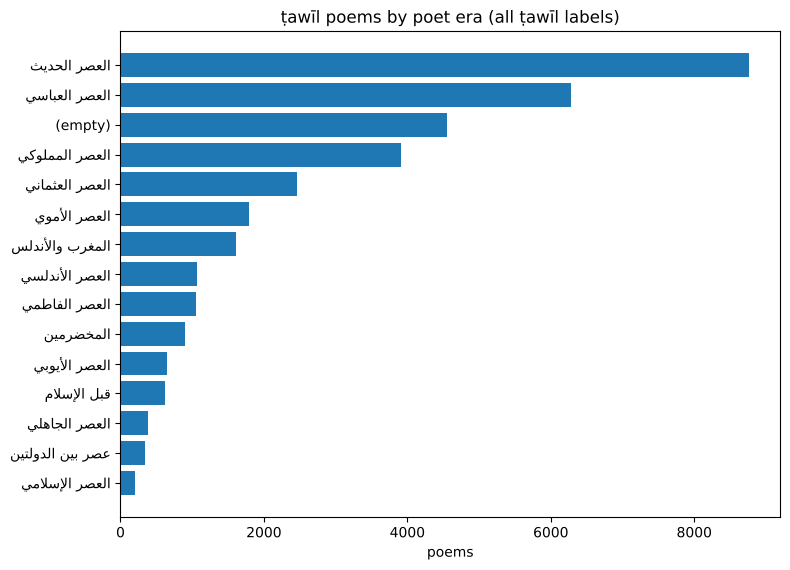

In [16]:
by_era = tawil["poet era"].fillna("(empty)").value_counts()
barh(by_era, "ṭawīl poems by poet era (all ṭawīl labels)", "poems")

**Observed.** Four labels name the *ṭawīl*: الطويل (19,746 poems),
بحر الطويل (14,823), بحر مجزوء الطويل (12) and بحر مشطور الطويل (1).
4,550 *ṭawīl* poems have no era.

**Interpretation.** The *ṭawīl* is well represented in Ashaar, but more than a
quarter of its poems belong to the modern era.

## Observations

Ashaar has 254,630 poems from several websites. Meter and era are missing for
about 40% of the poems, and their labels depend on the source: the same *baḥr*
or era appears under different names, and some meter labels are not *buḥūr*.
Most poems store one hemistich per string, but 24,378 have an odd number of
strings. The *ṭawīl* is the best represented *baḥr* (34,582 poems).

## Challenges

1. **Normalise the meter labels**: with or without بحر, spaces, variants, and
   labels that are not *buḥūr*.
2. **Missing metadata**: 40% of the poems have no meter, 42% no era.
3. **Era labels**: merge the categories that are the same, and check the
   doubtful ones.
4. **Poems with an odd number of strings**: exclude them.
5. **Vocalisation**: needs to be investigated.
6. **Duplicates across sources**, and **overlap with MetRec**: Ashaar includes
   `aldiwan.net` among its sources, and MetRec was collected from Aldiwan.